# SBS Detection: Peak Ratio Method 

This notebook include the codes to evaluate the peak ratio method for SBS detection. 

Author: Farhad Abdollahi (farhad.abdollahi.ctr@dot.gov)

Date: 09/30/2026

In [1]:
# Importing the required libraries. 
import os
import sys
import sqlite3
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from scripts.Sub04_FTIR_Analysis_Functions import Binary_to_Array, Gaussian_Function

In [2]:
# User defined variable. 
DB_File = pathlib.Path('T:\\ABML\\_Projects\\RD-2302 RA Rodeo\\Processed Data\\Binder Lab\\FTIR\\Rodeo_RA.db')

Read the database

In [3]:
# Read the Rodeo RA database. 
conn = sqlite3.connect(DB_File)
Data = pd.read_sql("SELECT * FROM FTIR", conn)
conn.close()
Data.head(3)

,id,Bnumber,Lab_Aging,RepNumber,FileName,ICO_Baseline,ICO_Tangential,ISO_Baseline,ISO_Tangential,Carbonyl_Area_Baseline,...,FileDirectory,RawWavenumber,RawWavenumber_shape,RawWavenumber_dtype,RawAbsorbance,RawAbsorbance_shape,RawAbsorbance_dtype,ALS_Lambda,ALS_Ratio,ALS_NumIter
0,1,7047,1PAV,1,B7047_FTIR_Rep1_1PAV.dpt,0.173085,0.081682,0.291345,0.269551,1.181007,...,T:\ABML\_Projects\RD-2302 RA Rodeo\Raw Data\Bi...,b'\x00\x00\x00\x00\x80\xfax@O\xe9`\xfd\x1f\x1b...,"(1765,)",float64,b'p_\x07\xce\x19Q\x9a?1\x94\x13\xed*\xa4\x9c?\...,"(1765,)",float64,1000000.0,0.1,150
1,2,7047,ORG,1,B7047_FTIR_Rep1_ORG.dpt,0.037728,0.008189,0.110768,0.073876,0.256957,...,T:\ABML\_Projects\RD-2302 RA Rodeo\Raw Data\Bi...,b'\x00\x00\x00\x00\x80\xfax@O\xe9`\xfd\x1f\x1b...,"(1765,)",float64,b'\xcep\x03>?\x8c\xa0?\xca7\xdb\xdc\x98\x9e\xa...,"(1765,)",float64,1000000.0,0.1,150
2,3,7047,RTFO,1,B7047_FTIR_Rep1_RTFO.dpt,0.040809,0.007890,0.110178,0.079099,0.278468,...,T:\ABML\_Projects\RD-2302 RA Rodeo\Raw Data\Bi...,b'\x00\x00\x00\x00\x80\xfax@O\xe9`\xfd\x1f\x1b...,"(1765,)",float64,"b'B`\xe5\xd0""\xdb\x99?,}\xe8\x82\xfa\x96\x99?\...","(1765,)",float64,1000000.0,0.1,150


___________

## Evaluating the Areas and Peaks

The interested areas and peaks are at wavenumbers of 966, 699, 1377, and 813. 

In [4]:
def Evaluate_SBS_Indices(Data, i):
    # Extract the Gaussian list and the pre-processed FTIR spectrum.
    GL = Binary_to_Array(Data.loc[i, 'Deconv_GaussianList'], 
                         Data.loc[i, 'Deconv_GaussianList_shape'], 
                         Data.loc[i, 'Deconv_GaussianList_dtype'])
    X = Binary_to_Array(Data.loc[i, 'Wavenumber'], Data.loc[i, 'Wavenumber_shape'], Data.loc[i, 'Wavenumber_dtype'])
    Y = Binary_to_Array(Data.loc[i, 'Absorption'], Data.loc[i, 'Absorption_shape'], Data.loc[i, 'Absorption_dtype'])
    # Identify the Gaussians for different bonds. 
    GL699  = GL[np.where((GL[:, 0] >= 685) & (GL[:, 0] <= 710))[0], :]      # Monosubstituted benzene ring $C-H$ out-of-plane rocking vibration of polystyrene
    GL813  = GL[np.where((GL[:, 0] >= 795) & (GL[:, 0] <= 830))[0], :]      # Aromatic ring $C-H$ out-of-plane rocking vibration
    GL966  = GL[np.where((GL[:, 0] >= 950) & (GL[:, 0] <= 980))[0], :]      # Trans-1,4-butadiene $C=C$ out-of-plane bending vibration
    GL1377 = GL[np.where((GL[:, 0] >= 1350) & (GL[:, 0] <= 1400))[0], :]    # Aliphatic methyl ($-CH_3$) symmetric deformation bending vibration
    # Calculating the areas and indices. 
    A699  = np.sum(np.abs(np.sqrt(2 * np.pi) * GL699[:, 1]  * GL699[:, 2]))
    A813  = np.sum(np.abs(np.sqrt(2 * np.pi) * GL813[:, 1]  * GL813[:, 2]))
    A966  = np.sum(np.abs(np.sqrt(2 * np.pi) * GL966[:, 1]  * GL966[:, 2]))
    A1377 = np.sum(np.abs(np.sqrt(2 * np.pi) * GL1377[:, 1] * GL1377[:, 2]))
    H699  = max(list(np.abs(GL699[:, 2])) + [0])
    H813  = max(list(np.abs(GL813[:, 2])) + [0])
    H966  = max(list(np.abs(GL966[:, 2])) + [0])
    H1377 = max(list(np.abs(GL1377[:, 2])) + [0])
    A6002000 = np.trapezoid(Y, X)
    Ra1   = A966 / A1377
    Rh1   = H966 / H1377
    Ra2   = A966 / A813
    Rh2   = H966 / H813
    Ra699 = A699 / A1377
    Rh699 = H699 / H1377
    Ra20  = A966 / (A966 + A813)
    Rh20  = H966 / (H966 + H813)
    I966  = A966 / A6002000
    I699  = A699 / A6002000
    # Return the indices. 
    return {
        'Ra1': Ra1, 'Rh1': Rh1, 'Ra2': Ra2, 'Rh2': Rh2, 'Ra20': Ra20, 'Rh20': Rh20, 
        'Ra699': Ra699, 'Rh699': Rh699, 'I966': I966, 'I699': I699}

In [5]:
# Add the new fields. 
for key in ['Ra1', 'Rh1', 'Ra2', 'Rh2', 'Ra20', 'Rh20', 'Ra699', 'Rh699', 'I966', 'I699']:
    Data[key] = 0.0
for i in Data.index:
    if Data.loc[i, 'IsOutlier']:
        continue
    Res = Evaluate_SBS_Indices(Data, i)
    for key in ['Ra1', 'Rh1', 'Ra2', 'Rh2', 'Ra20', 'Rh20', 'Ra699', 'Rh699', 'I966', 'I699']:
        Data.loc[i, key] = Res[key]

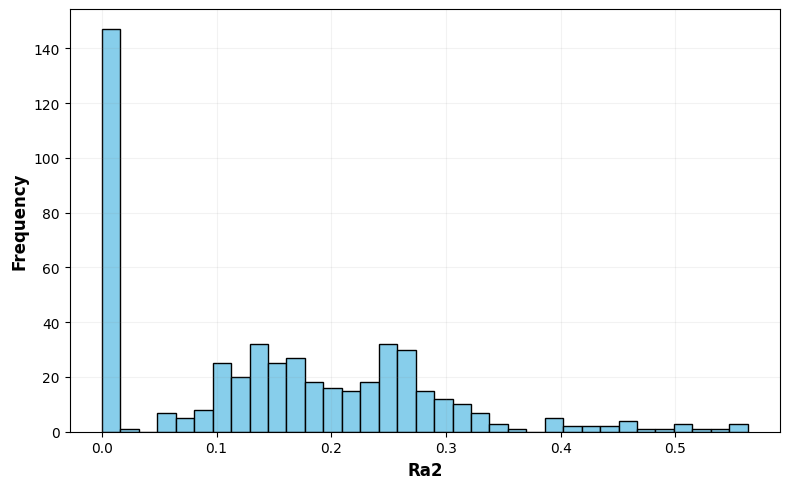

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))
Data['Ra2'].hist(ax=ax, bins=35, ls='-', edgecolor='k', facecolor='skyblue')
ax.grid(which='both', color='gray', alpha=0.1)
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold', color='k')
ax.set_xlabel('Ra2', fontsize=12, fontweight='bold', color='k')
fig.tight_layout()

_________

## Evaluate the effect of aging on the Indices. 

In [18]:
BnumberUnique = Data['Bnumber'].unique()
for bnum in BnumberUnique:
    df = Data[Data['Bnumber'] == bnum]
    for age in df['Lab_Aging'].unique():
        print(f'{bnum}, {age}, {df[df["Lab_Aging"] == age]["Ra2"].mean()}')

7047, 1PAV, 0.19057222724901393
7047, ORG, 0.15168675095165188
7047, RTFO, 0.17713737292556833
7048, 1PAV, 0.24460291405334098
7048, ORG, 0.2550587644826555
7048, RTFO, 0.24941116584379278
7049, 1PAV, 0.0
7049, ORG, 0.10437473429143318
7049, RTFO, 0.12225155771094394
7050, 1PAV, 0.35515389564471517
7050, ORG, 0.23385770773993167
7050, RTFO, 0.29163129002870497
7051, 1PAV, 0.059989224567678856
7051, ORG, 0.01713515974049112
7051, RTFO, 0.06715702050970972
7052, 1PAV, 0.2298512277464471
7052, ORG, 0.1614959866174066
7052, RTFO, 0.18497894846157806
7053, 1PAV, 0.08961944462290632
7053, ORG, 0.09360909692697568
7053, RTFO, 0.09249586109761855
7054, 1PAV, 0.07434616935234549
7054, 2PAV, 0.13684146083600388
7054, ORG, 0.0462776444662596
7054, RTFO, 0.09752664155480918
7055, 1PAV, 0.03845335539185744
7055, ORG, 0.0
7055, RTFO, 0.03934992525354252
7056, 1PAV, 0.24539486452932532
7056, ORG, 0.18324987699779202
7056, RTFO, 0.24649969161143978
7057, 1PAV, 0.2771159532201289
7057, 2PAV, 0.28256107

In [43]:
Data[(Data['Bnumber'] == 7050) & (Data['IsOutlier'] == 0)].sort_values(by=['Lab_Aging'])

,id,Bnumber,Lab_Aging,RepNumber,FileName,ICO_Baseline,ICO_Tangential,ISO_Baseline,ISO_Tangential,Carbonyl_Area_Baseline,...,Ra1,Rh1,Ra2,Rh2,Ra20,Rh20,Ra699,Rh699,I966,I699
27,28,7050,1PAV,1,B7050_FTIR_Rep1_1PAV.dpt,0.108534,0.044704,0.264007,0.196240,0.761938,...,0.143233,0.433539,0.312929,0.816824,0.238344,0.449589,0.121132,0.571475,0.008517,0.007203
30,31,7050,1PAV,2,B7050_FTIR_Rep2_1PAV.dpt,0.082879,0.035061,0.242005,0.168051,0.666268,...,0.472393,0.437588,0.439417,0.956926,0.305274,0.488994,0.317079,0.525187,0.011164,0.007493
33,34,7050,1PAV,3,B7050_FTIR_Rep3_1PAV.dpt,0.094305,0.037170,0.250444,0.184379,0.658954,...,0.140894,0.396624,0.313115,0.772170,0.238452,0.435720,0.123724,0.517945,0.007732,0.006790
28,29,7050,ORG,1,B7050_FTIR_Rep1_ORG.dpt,0.025536,0.002832,0.041879,0.057944,0.176724,...,0.206690,0.332190,0.218454,0.628773,0.179288,0.386041,0.252179,0.543347,0.006496,0.007926
31,32,7050,ORG,2,B7050_FTIR_Rep2_ORG.dpt,0.026914,0.002127,0.115297,0.080220,0.185136,...,0.219883,0.333042,0.252303,0.626056,0.201471,0.385015,0.223278,0.518439,0.006968,0.007075
34,35,7050,ORG,3,B7050_FTIR_Rep3_ORG.dpt,0.019414,0.005714,0.036088,0.048573,0.133192,...,0.197927,0.334682,0.230816,0.630531,0.187531,0.386703,0.235827,0.548253,0.006071,0.007234
29,30,7050,RTFO,1,B7050_FTIR_Rep1_RTFO.dpt,0.044366,0.008347,0.116282,0.076422,0.301699,...,0.275791,0.385786,0.306467,0.716436,0.234577,0.417398,0.253698,0.519021,0.007586,0.006978
32,33,7050,RTFO,2,B7050_FTIR_Rep2_RTFO.dpt,0.060754,0.009432,0.133409,0.081560,0.412850,...,0.268614,0.374624,0.287175,0.748046,0.223105,0.427933,0.251069,0.507446,0.007422,0.006937
35,36,7050,RTFO,3,B7050_FTIR_Rep3_RTFO.dpt,0.052439,0.011521,0.132548,0.090284,0.356393,...,0.270104,0.366288,0.281251,0.710625,0.219513,0.415418,0.271639,0.500971,0.007340,0.007381


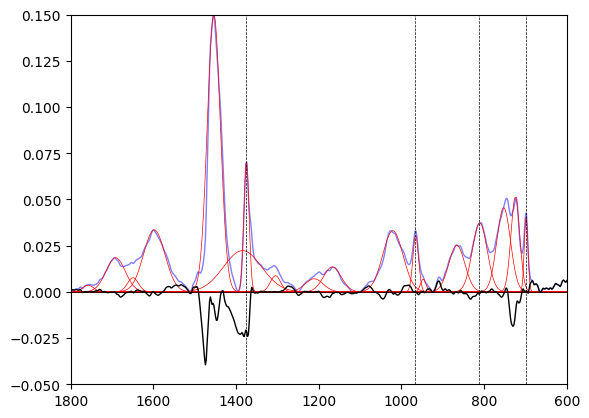

In [51]:
for i in [27]:
    X = Binary_to_Array(Data.loc[i, 'Wavenumber'], Data.loc[i, 'Wavenumber_shape'], Data.loc[i, 'Wavenumber_dtype'])
    Y = Binary_to_Array(Data.loc[i, 'Absorption'], Data.loc[i, 'Absorption_shape'], Data.loc[i, 'Absorption_dtype'])
    plt.plot(X, Y, ls='-', lw=1, color='b', alpha=0.5)
    GL = Binary_to_Array(Data.loc[i, 'Deconv_GaussianList'], 
                             Data.loc[i, 'Deconv_GaussianList_shape'], 
                             Data.loc[i, 'Deconv_GaussianList_dtype'])
    XX = np.linspace(600, 1800, num=1000)
    YY = Y.copy()
    for j in range(GL.shape[0]):
        plt.plot(XX, Gaussian_Function(XX, GL[j, 2], GL[j, 0], GL[j, 1]), ls='-', lw=0.5, color='r')
        YY -= Gaussian_Function(X, GL[j, 2], GL[j, 0], GL[j, 1])
    plt.plot(X, YY, ls='-', lw=1, color='k', alpha=1.0)
plt.xlim([1800, 600])
plt.ylim([-0.05, 0.15])
plt.axvline(966, ls='--', color='k', lw=0.5)
plt.axvline(813, ls='--', color='k', lw=0.5)
plt.axvline(699, ls='--', color='k', lw=0.5)
plt.axvline(1377, ls='--', color='k', lw=0.5)
plt.axhline(0, ls='-', color='k', lw=0.5)

## Evaluate the effect of aging on different peaks. 

## How consistent are the ratios with different aging levels. 

## try to identify the SBS modified ones and train a classification algorithm maybe that gives us a probability.

## Try to get the results from different projects, PTF, RA, and different MATC projects. 